In [1]:
import duckdb
import pandas as pd

con = duckdb.connect('data/olist.duckdb')

import glob
for filepath in glob.glob('data/*.csv'):
    table_name = filepath.split('/')[-1].replace('.csv', '').replace('olist_', '').replace('_dataset', '')
    con.execute(f"CREATE OR REPLACE TABLE {table_name} AS SELECT * FROM read_csv_auto('{filepath}')")
    print(f"Loaded: {table_name}")

con.execute("SHOW TABLES").df()

Loaded: sellers
Loaded: product_category_name_translation
Loaded: orders
Loaded: order_items
Loaded: customers
Loaded: geolocation
Loaded: order_payments
Loaded: order_reviews
Loaded: products


,name
0,customers
1,geolocation
2,order_items
3,order_payments
4,order_reviews
5,orders
6,product_category_name_translation
7,products
8,sellers


In [2]:
# Row counts for each table
tables = ['customers', 'orders', 'order_items', 'order_payments', 
          'order_reviews', 'products', 'sellers', 'geolocation',
          'product_category_name_translation']

for t in tables:
    n = con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
    print(f"{t}: {n:,}")

customers: 99,441
orders: 99,441
order_items: 112,650
order_payments: 103,886
order_reviews: 99,224
products: 32,951
sellers: 3,095
geolocation: 1,000,163
product_category_name_translation: 71


# Olist E-Commerce: Revenue and Seller Performance Analysis

This notebook analyzes the Olist Brazilian e-commerce dataset using SQL (DuckDB) 
to answer two core business questions:

1. **Revenue Analysis** — How does revenue trend over time, and which product 
   categories drive the most value?
2. **Seller Performance** — Which sellers generate the most revenue, and how does 
   delivery speed relate to customer satisfaction?

The dataset covers ~99K orders placed on the Olist marketplace between 
2016 and 2018 across Brazil.

## Setup

In [4]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

con = duckdb.connect('data/olist.duckdb')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

## Section 1: Revenue Analysis

We join `orders`, `order_items`, and `product_category_name_translation` to build 
a clean revenue table with English category names and parsed order dates.

In [5]:
monthly_revenue = con.execute("""
    WITH revenue_base AS (
        SELECT
            DATE_TRUNC('month', o.order_purchase_timestamp) AS month,
            SUM(oi.price + oi.freight_value)                AS total_revenue,
            COUNT(DISTINCT o.order_id)                      AS n_orders,
            SUM(oi.price + oi.freight_value) / 
                COUNT(DISTINCT o.order_id)                  AS avg_order_value
        FROM orders o
        JOIN order_items oi ON o.order_id = oi.order_id
        WHERE o.order_status = 'delivered'
        GROUP BY 1
        ORDER BY 1
    )
    SELECT * FROM revenue_base
""").df()

print(monthly_revenue.shape)
print(monthly_revenue.head())

(23, 4)
       month  total_revenue  n_orders  avg_order_value
0 2016-09-01         143.46         1       143.460000
1 2016-10-01       46490.66       265       175.436453
2 2016-12-01          19.62         1        19.620000
3 2017-01-01      127482.37       750       169.976493
4 2017-02-01      271239.32      1653       164.089123


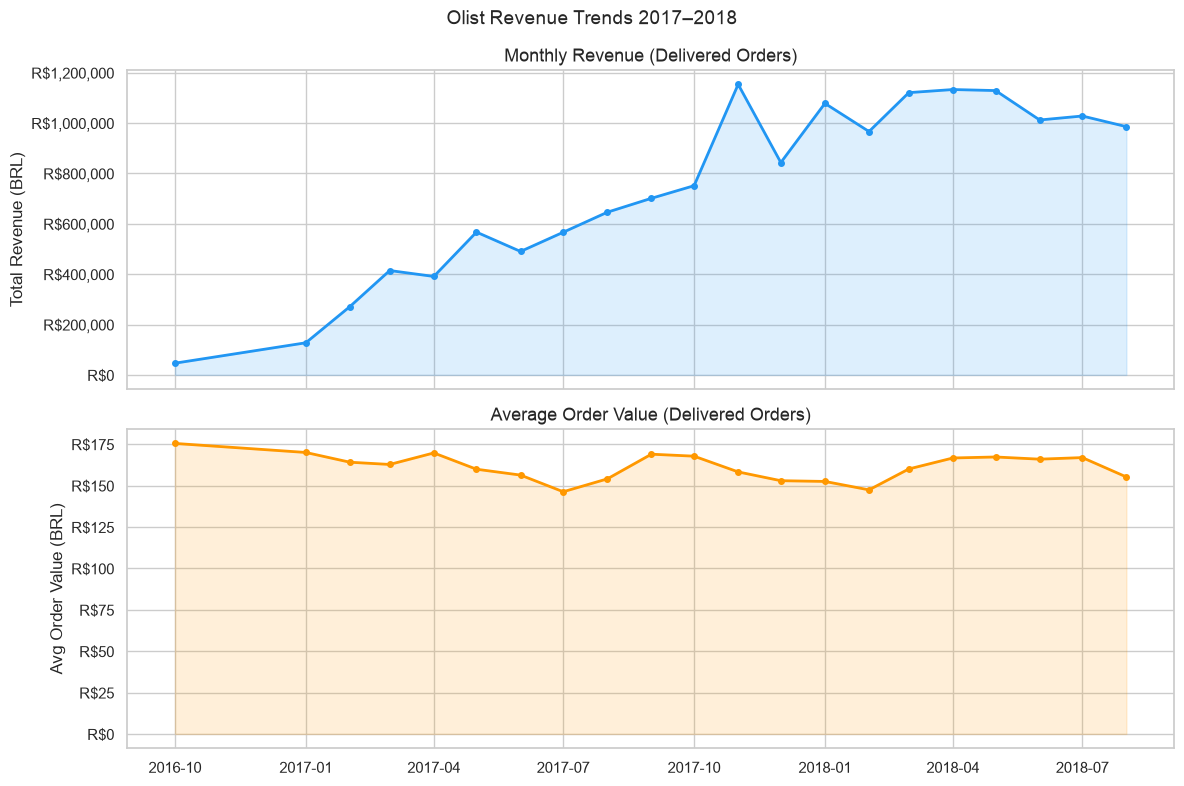

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Drop the outlier months with <10 orders (2016-09, 2016-12)
monthly_plot = monthly_revenue[monthly_revenue['n_orders'] >= 10].copy()

# Total revenue
axes[0].plot(monthly_plot['month'], monthly_plot['total_revenue'], 
             color='#2196F3', linewidth=2, marker='o', markersize=4)
axes[0].fill_between(monthly_plot['month'], monthly_plot['total_revenue'], 
                     alpha=0.15, color='#2196F3')
axes[0].set_title('Monthly Revenue (Delivered Orders)', fontsize=13)
axes[0].set_ylabel('Total Revenue (BRL)')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'R${x:,.0f}'))

# Average order value
axes[1].plot(monthly_plot['month'], monthly_plot['avg_order_value'],
             color='#FF9800', linewidth=2, marker='o', markersize=4)
axes[1].fill_between(monthly_plot['month'], monthly_plot['avg_order_value'],
                     alpha=0.15, color='#FF9800')
axes[1].set_title('Average Order Value (Delivered Orders)', fontsize=13)
axes[1].set_ylabel('Avg Order Value (BRL)')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'R${x:,.0f}'))

plt.suptitle('Olist Revenue Trends 2017–2018', fontsize=14)
plt.tight_layout()
plt.show()

### Monthly Revenue Trends

Revenue grows consistently from early 2017 through mid-2018, reflecting Olist's 
rapid marketplace expansion during this period. Average order value remains flat 
at approximately R$160–180 throughout, indicating that revenue growth is driven 
primarily by order volume rather than increased spend per order. This suggests 
that upsell and cross-sell strategies — rather than customer acquisition alone — 
may represent an untapped growth lever for the platform.

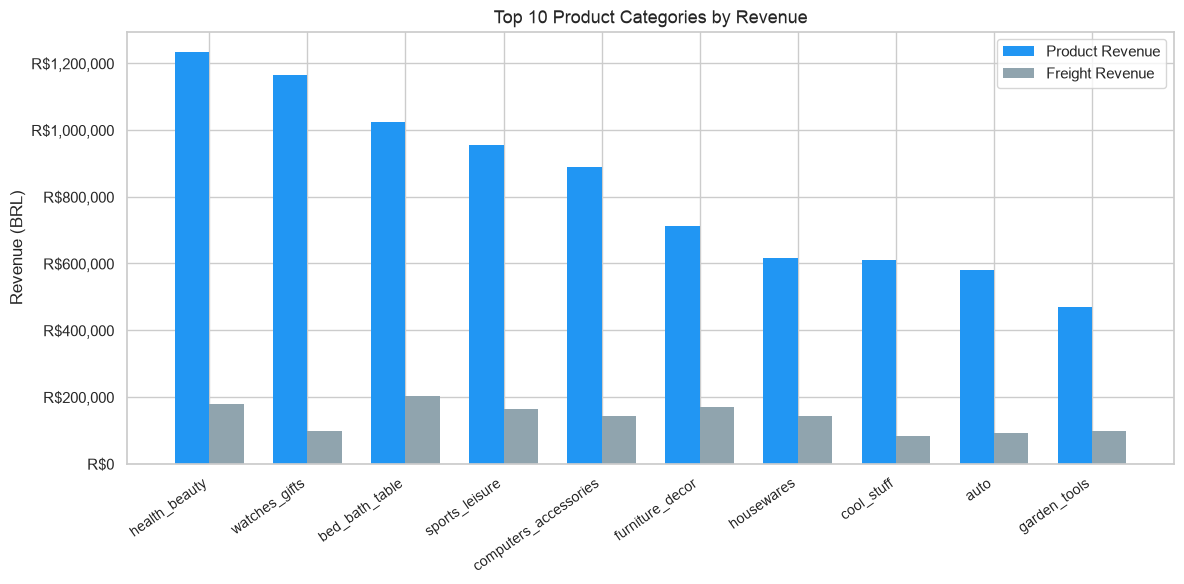

             category  total_revenue  freight_pct
        health_beauty     1412089.53         12.7
        watches_gifts     1264333.12          7.8
       bed_bath_table     1225209.26         16.5
       sports_leisure     1118256.91         14.6
computers_accessories     1032723.77         13.9
      furniture_decor      880329.92         19.1
           housewares      758392.25         18.8
           cool_stuff      691680.89         11.8
                 auto      669454.75         13.5
         garden_tools      567145.68         17.0


In [ ]:
category_revenue = con.execute("""
    WITH cat_rev AS (
        SELECT
            t.product_category_name_english  AS category,
            SUM(oi.price)                    AS product_revenue,
            SUM(oi.freight_value)            AS freight_revenue,
            SUM(oi.price + oi.freight_value) AS total_revenue,
            COUNT(DISTINCT o.order_id)       AS n_orders
        FROM orders o
        JOIN order_items oi  ON o.order_id  = oi.order_id
        JOIN products p      ON oi.product_id = p.product_id
        JOIN product_category_name_translation t 
             ON p.product_category_name = t.product_category_name
        WHERE o.order_status = 'delivered'
        GROUP BY 1
        ORDER BY total_revenue DESC
    )
    SELECT * FROM cat_rev
    LIMIT 10
""").df()

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(category_revenue))
width = 0.35

bars1 = ax.bar(x - width/2, category_revenue['product_revenue'], width,
               label='Product Revenue', color='#2196F3', edgecolor='none')
bars2 = ax.bar(x + width/2, category_revenue['freight_revenue'], width,
               label='Freight Revenue', color='#90A4AE', edgecolor='none')

ax.set_xticks(x)
ax.set_xticklabels(category_revenue['category'], rotation=35, ha='right', fontsize=10)
ax.set_ylabel('Revenue (BRL)')
ax.set_title('Top 10 Product Categories by Revenue', fontsize=13)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'R${x:,.0f}'))
ax.legend()

plt.tight_layout()
plt.show()

# Compute freight as % of total
category_revenue['freight_pct'] = (category_revenue['freight_revenue'] / 
                                    category_revenue['total_revenue'] * 100).round(1)

### Revenue by Product Category

Health & beauty leads all categories in total revenue (R$1.41M), followed by 
watches & gifts and bed, bath & table. Freight costs vary meaningfully across 
categories: furniture and home goods carry the highest freight burden (~19% of 
total revenue), reflecting the cost of shipping bulky items across Brazil's large 
geography. Watches and gifts, by contrast, have the lowest freight ratio (7.8%) — 
small, high-value items where shipping costs are minimal relative to product price. 
This suggests that furniture and home goods sellers face a structural cost 
disadvantage that may compress their margins relative to other categories.

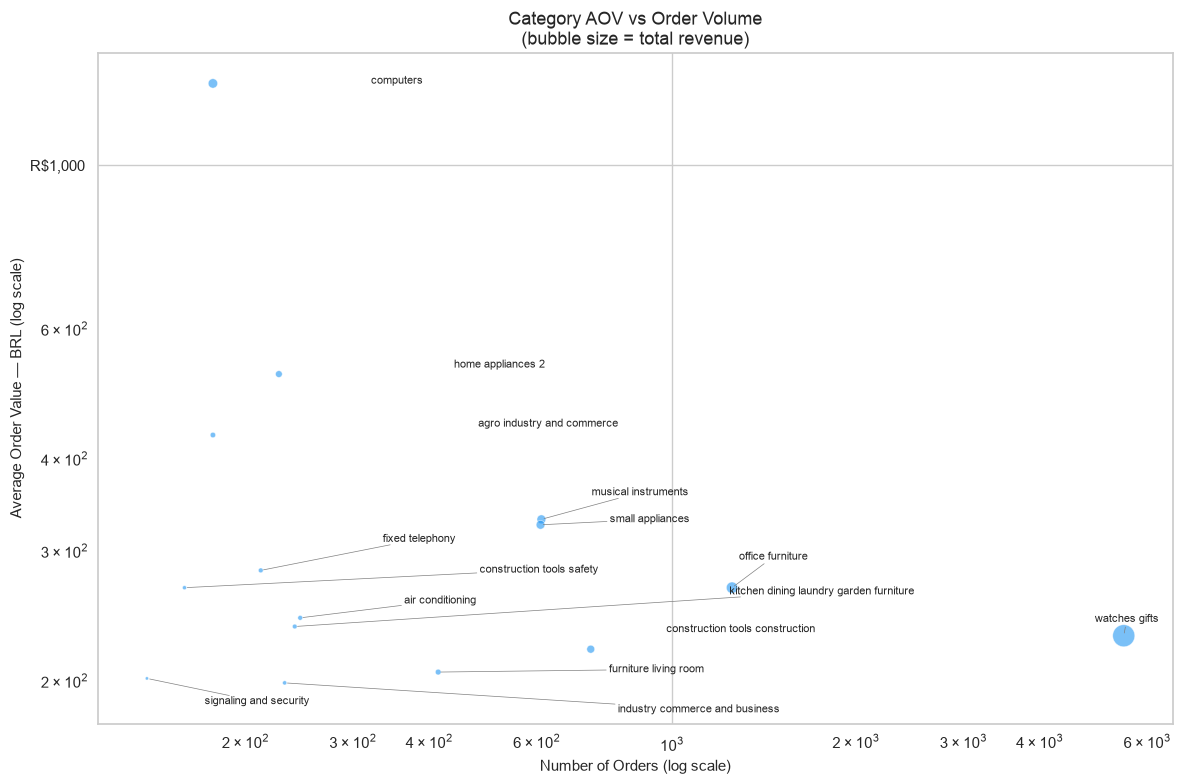

In [ ]:
aov_category = con.execute("""
    WITH order_totals AS (
        SELECT
            o.order_id,
            t.product_category_name_english AS category,
            SUM(oi.price + oi.freight_value) AS order_value
        FROM orders o
        JOIN order_items oi ON o.order_id = oi.order_id
        JOIN products p ON oi.product_id = p.product_id
        JOIN product_category_name_translation t 
             ON p.product_category_name = t.product_category_name
        WHERE o.order_status = 'delivered'
        GROUP BY o.order_id, t.product_category_name_english
    )
    SELECT
        category,
        COUNT(order_id)      AS n_orders,
        AVG(order_value)     AS avg_order_value,
        SUM(order_value)     AS total_revenue
    FROM order_totals
    GROUP BY category
    HAVING COUNT(order_id) >= 100
    ORDER BY avg_order_value DESC
    LIMIT 15
""").df()

# Get full AOV table without LIMIT for context, but label top 15
aov_plot = aov_category.copy()

fig, ax = plt.subplots(figsize=(12, 8))

scatter = ax.scatter(aov_plot['n_orders'], aov_plot['avg_order_value'],
                     s=aov_plot['total_revenue'] / 5000,
                     alpha=0.6, color='#2196F3', edgecolor='white', linewidth=0.5)

# Labels with adjustText for non-overlapping placement
from adjustText import adjust_text
texts = []
for _, row in aov_plot.iterrows():
    texts.append(ax.text(row['n_orders'], row['avg_order_value'],
                         row['category'].replace('_', ' '), fontsize=8))
adjust_text(texts, arrowprops=dict(arrowstyle='-', color='gray', lw=0.5))

ax.set_xscale('log')
ax.set_yscale('log')

ax.set_xlabel('Number of Orders (log scale)', fontsize=11)
ax.set_ylabel('Average Order Value — BRL (log scale)', fontsize=11)
ax.set_title('Category AOV vs Order Volume\n(point size = total revenue)', fontsize=13)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'R${x:,.0f}'))

plt.tight_layout()
plt.show()

### Average Order Value vs Order Volume

No category occupies the high-volume, high-AOV quadrant — a pattern typical of 
competitive marketplaces where popular categories face price pressure. Computers 
and home appliances command the highest AOVs (R$1,290 and R$521 respectively) but 
remain niche in volume. Watches & gifts and office furniture are notable exceptions 
on the left: moderate-to-high AOV with meaningful order volume, making them the 
most balanced categories by revenue efficiency. High-volume categories like 
health & beauty and bed, bath & table achieve top-line revenue through order 
quantity rather than ticket size.

In [14]:
repeat_customers = con.execute("""
    WITH customer_orders AS (
        SELECT
            customer_unique_id,
            COUNT(DISTINCT o.order_id) AS n_orders
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        WHERE o.order_status = 'delivered'
        GROUP BY customer_unique_id
    )
    SELECT
        n_orders,
        COUNT(*) AS n_customers,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct_customers
    FROM customer_orders
    GROUP BY n_orders
    ORDER BY n_orders
""").df()

print(repeat_customers.head(10))
print(f"\nRepeat customer rate: {repeat_customers[repeat_customers['n_orders'] > 1]['n_customers'].sum() / repeat_customers['n_customers'].sum() * 100:.1f}%")

   n_orders  n_customers  pct_customers
0         1        90557          97.00
1         2         2573           2.76
2         3          181           0.19
3         4           28           0.03
4         5            9           0.01
5         6            5           0.01
6         7            3           0.00
7         9            1           0.00
8        15            1           0.00

Repeat customer rate: 3.0%


In [15]:
repeat_categories = con.execute("""
    WITH customer_orders AS (
        SELECT
            c.customer_unique_id,
            COUNT(DISTINCT o.order_id) AS n_orders
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        WHERE o.order_status = 'delivered'
        GROUP BY c.customer_unique_id
    ),
    repeat_customers AS (
        SELECT customer_unique_id
        FROM customer_orders
        WHERE n_orders > 1
    ),
    repeat_purchases AS (
        SELECT
            t.product_category_name_english AS category,
            COUNT(DISTINCT o.order_id)      AS n_orders,
            SUM(oi.price)                   AS total_revenue
        FROM orders o
        JOIN customers c      ON o.customer_id   = c.customer_id
        JOIN order_items oi   ON o.order_id      = oi.order_id
        JOIN products p       ON oi.product_id   = p.product_id
        JOIN product_category_name_translation t 
             ON p.product_category_name = t.product_category_name
        WHERE o.order_status = 'delivered'
          AND c.customer_unique_id IN (SELECT customer_unique_id FROM repeat_customers)
        GROUP BY t.product_category_name_english
        ORDER BY n_orders DESC
        LIMIT 10
    )
    SELECT * FROM repeat_purchases
""").df()

print(repeat_categories.to_string(index=False))

                category  n_orders  total_revenue
          bed_bath_table       842       94838.43
          sports_leisure       575       71258.13
         furniture_decor       574       62158.94
           health_beauty       485       54463.30
   computers_accessories       395       60577.08
              housewares       341       33722.96
           watches_gifts       273       52202.95
fashion_bags_accessories       218       16420.38
                    toys       195       22210.49
            garden_tools       184       19001.22


### Repeat Customer Behavior

Only 3% of Olist customers place more than one order — a remarkably low repeat 
rate that suggests revenue growth is driven almost entirely by new customer 
acquisition rather than retention.

Among the small cohort of repeat buyers, bed, bath & table is the top category 
by order volume, overtaking health & beauty which leads overall. This suggests 
bed_bath_table has stronger natural repurchase dynamics — customers return to 
complete a home setup — while health & beauty purchases may be more exploratory 
or one-time in nature. Improving retention in health & beauty, the platform's 
top revenue category, represents a meaningful untapped opportunity.

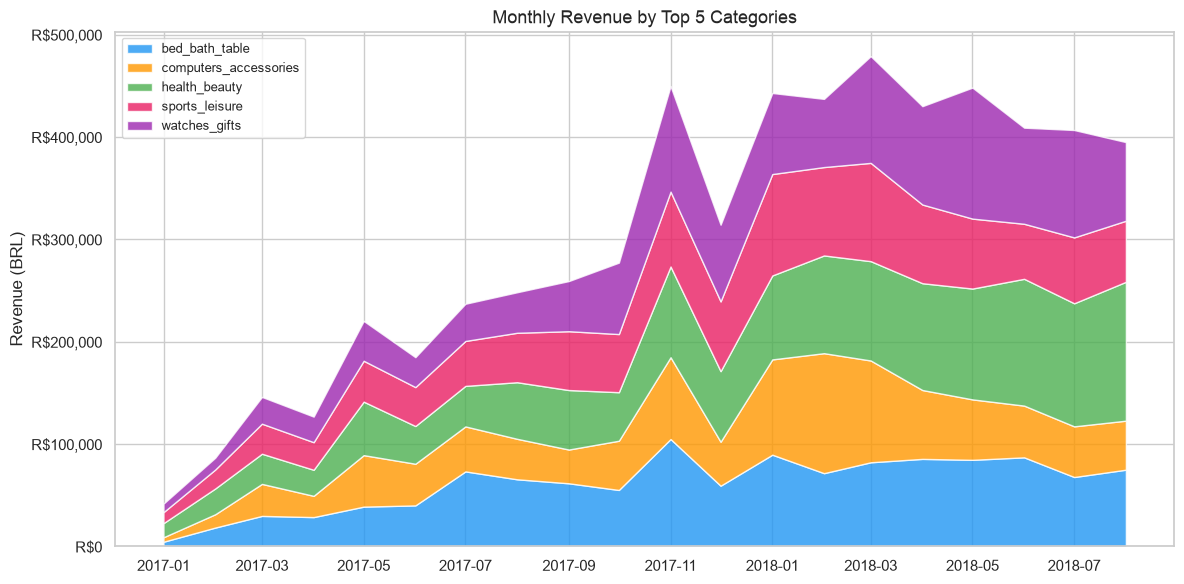

In [16]:
top5_cats = category_revenue.nlargest(5, 'total_revenue')['category'].tolist()

category_monthly = con.execute(f"""
    SELECT
        DATE_TRUNC('month', o.order_purchase_timestamp) AS month,
        t.product_category_name_english                 AS category,
        SUM(oi.price + oi.freight_value)                AS revenue
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    JOIN products p ON oi.product_id = p.product_id
    JOIN product_category_name_translation t 
         ON p.product_category_name = t.product_category_name
    WHERE o.order_status = 'delivered'
      AND t.product_category_name_english IN ({str(top5_cats)[1:-1]})
    GROUP BY 1, 2
    ORDER BY 1
""").df()

# Pivot for stacked area
pivot = category_monthly.pivot(index='month', columns='category', values='revenue').fillna(0)
pivot = pivot[pivot.index >= '2017-01-01']

fig, ax = plt.subplots(figsize=(12, 6))

colors = ['#2196F3', '#FF9800', '#4CAF50', '#E91E63', '#9C27B0']
ax.stackplot(pivot.index, pivot.T.values, labels=pivot.columns, colors=colors, alpha=0.8)

ax.set_title('Monthly Revenue by Top 5 Categories', fontsize=13)
ax.set_ylabel('Revenue (BRL)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'R${x:,.0f}'))
ax.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()

### Monthly Revenue by Top 5 Categories

Revenue growth from 2017 through mid-2018 is broad-based across all top categories, 
suggesting healthy marketplace expansion rather than dependence on any single product 
area. Watches & gifts shows the strongest seasonality, with a pronounced spike in 
November 2017 consistent with Black Friday demand — a major commercial event in 
Brazil. Health & beauty, by contrast, grows steadily with minimal seasonality, 
making it the most reliable revenue contributor despite leading in total revenue. 
The step-change in overall revenue visible in late 2017 reflects both seasonal 
effects and apparent acceleration in platform growth.

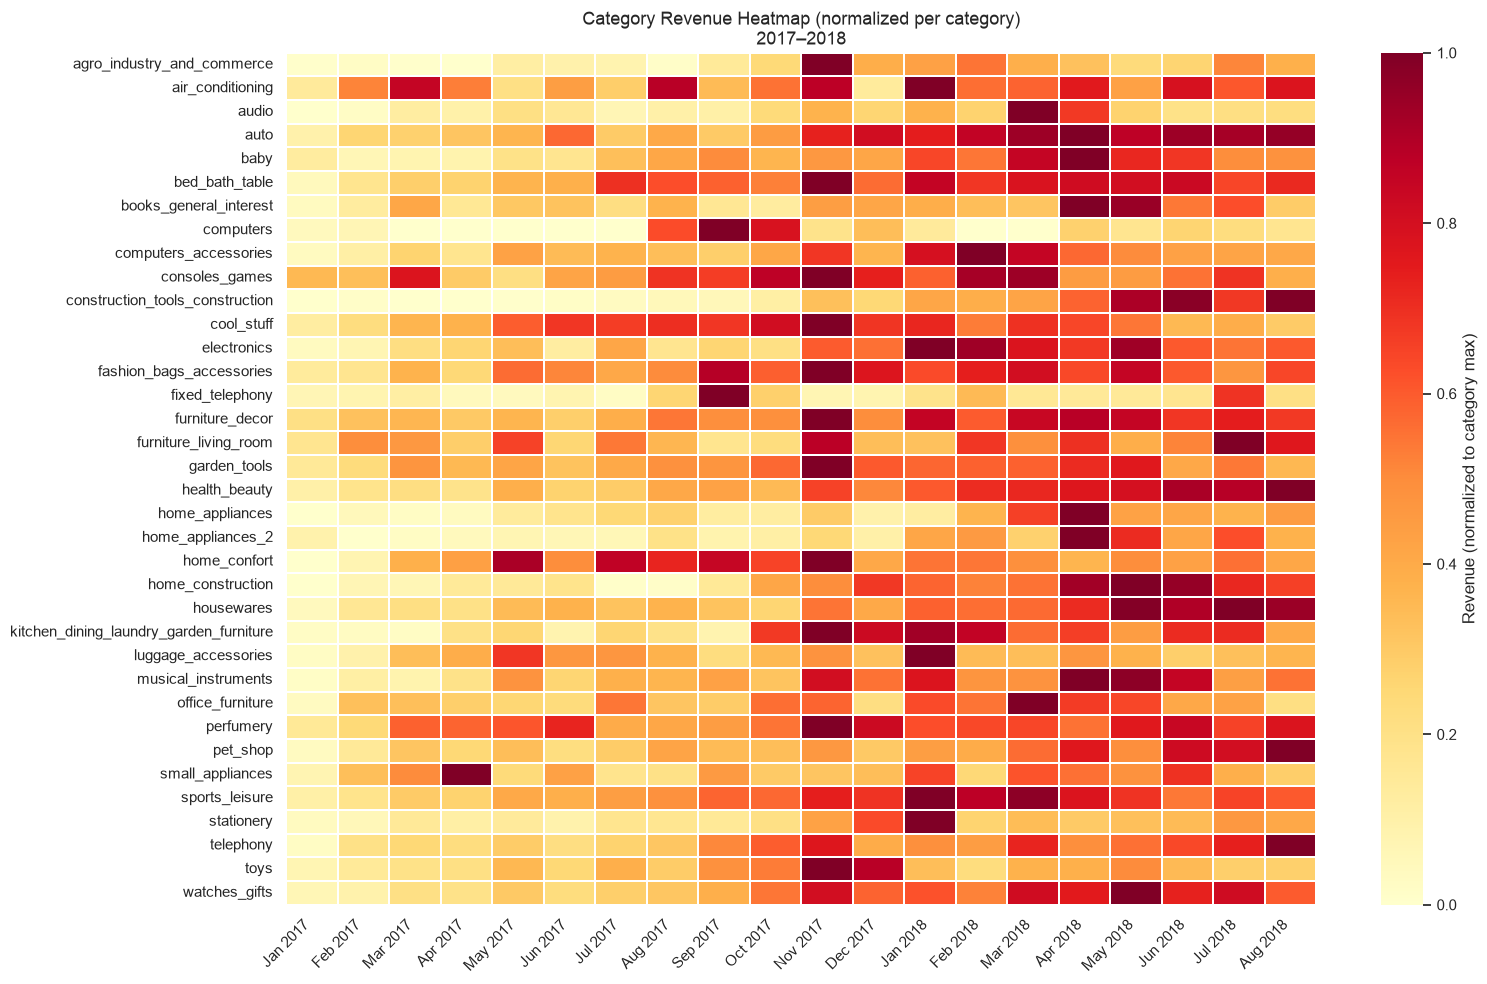

In [17]:
# Pivot all categories (not just top 5) with enough orders
cat_month_all = con.execute("""
    SELECT
        DATE_TRUNC('month', o.order_purchase_timestamp) AS month,
        t.product_category_name_english                 AS category,
        SUM(oi.price + oi.freight_value)                AS revenue
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    JOIN products p ON oi.product_id = p.product_id
    JOIN product_category_name_translation t 
         ON p.product_category_name = t.product_category_name
    WHERE o.order_status = 'delivered'
    GROUP BY 1, 2
    ORDER BY 1
""").df()

# Filter to 2017+ and categories with decent volume
cat_month_all = cat_month_all[cat_month_all['month'] >= '2017-01-01']

# Pivot
heatmap_pivot = cat_month_all.pivot(index='category', columns='month', values='revenue').fillna(0)

# Keep only categories with total revenue > 50k
heatmap_pivot = heatmap_pivot[heatmap_pivot.sum(axis=1) > 50000]

# Normalize each row by its own max so colors reflect growth pattern not absolute size
heatmap_norm = heatmap_pivot.div(heatmap_pivot.max(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(16, 10))

sns.heatmap(heatmap_norm, cmap='YlOrRd', ax=ax,
            linewidths=0.3, linecolor='white',
            cbar_kws={'label': 'Revenue (normalized to category max)'})

ax.set_title('Category Revenue Heatmap (normalized per category)\n2017–2018', fontsize=13)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_xticklabels([pd.Timestamp(t.get_text()).strftime('%b %Y') 
                    for t in ax.get_xticklabels()], rotation=45, ha='right')

plt.tight_layout()
plt.show()

### Category Revenue Heatmap

Normalizing each category to its own peak revenue reveals distinct growth trajectories 
across the platform. The November 2017 Black Friday spike is visible across nearly all 
categories, confirming it as a platform-wide demand event. Health & beauty, sports & 
leisure, and construction tools show consistently darkening patterns through August 2018, 
suggesting continued growth momentum. Consoles & games and home comfort show early 
strength followed by plateau or decline — possible trend-driven categories that peaked 
early. Pet shop and telephony emerge strongly in mid-to-late 2018, indicative of newer 
category expansion on the platform.

## Section 2: Seller Performance

We evaluate sellers across three dimensions — revenue, delivery speed, and customer 
satisfaction — and examine whether faster delivery is associated with higher review 
scores. Analysis is restricted to sellers with 50 or more delivered orders to ensure 
stable estimates (418 sellers).

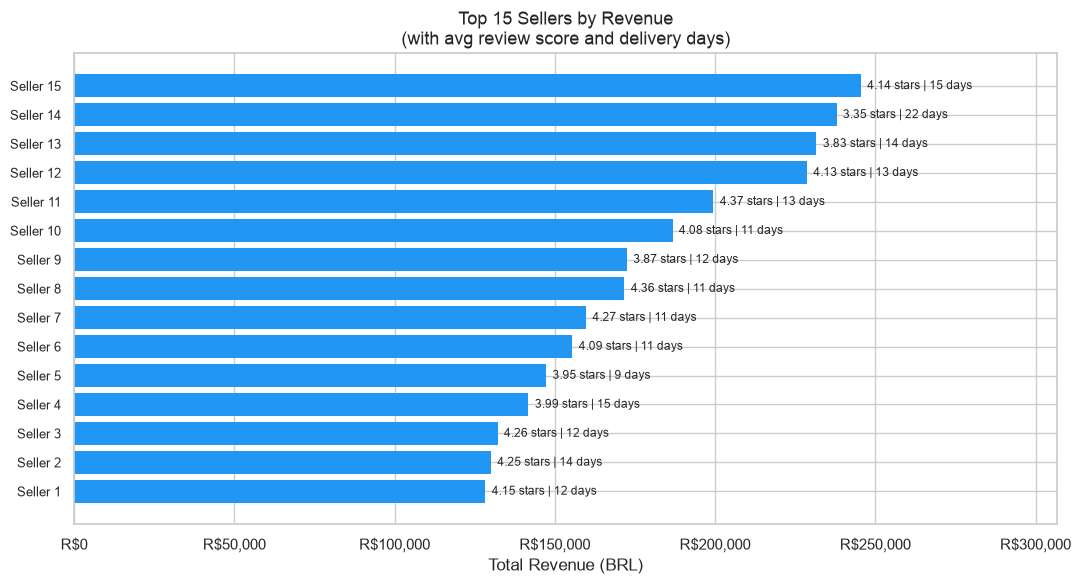

                           seller_id  n_orders  total_revenue  \
14  cc419e0650a3c5ba77189a1882b7556a      1647      128302.61   
13  a1043bafd471dff536d0c462352beb48       700      130034.00   
12  46dc3b2cc0980fb8ec44634e21d2718e       497      132102.09   
11  1f50f920176fa81dab994f9023523100      1394      141763.13   
10  6560211a19b47992c3666cc44a7e94c0      1805      147246.54   
9   955fee9216a65b617aa5c0531780ce60      1253      155447.29   
8   7a67c85e85bb2ce8582c35f2203ad736      1137      159721.05   
7   7e93a43ef30c4f03f38b393420bc753a       318      171706.63   
6   1025f0e2d44d7041d6cf58b6550e0bfa       902      172469.96   
5   da8622b14eb17ae2831f4ac5b9dab84a      1305      186715.03   
4   fa1c13f2614d7b5c4749cbc52fecda94       574      199493.51   
3   53243585a1d6dc2643021fd1853d8905       346      228644.09   
2   4a3ca9315b744ce9f8e9374361493884      1753      231619.99   
1   7c67e1448b00f6e969d365cea6b010ab       967      237880.59   
0   4869f7a5dfa277a7dca64

In [ ]:
fig, ax = plt.subplots(figsize=(11, 6))

top15 = seller_performance.nlargest(15, 'total_revenue').sort_values('total_revenue')

bars = ax.barh(range(len(top15)), top15['total_revenue'], 
               color='#2196F3', edgecolor='none')

# Annotate with avg review score
for bar, (_, row) in zip(bars, top15.iterrows()):
    ax.text(bar.get_width() + 2000, bar.get_y() + bar.get_height()/2,
f'{row["avg_review_score"]:.2f} stars | {row["avg_delivery_days"]:.0f} days',
            va='center', fontsize=8.5)

ax.set_yticks(range(len(top15)))
ax.set_yticklabels([f'Seller {i+1}' for i in range(len(top15))], fontsize=9)
ax.set_xlabel('Total Revenue (BRL)')
ax.set_title('Top 15 Sellers by Revenue\n(with avg review score and delivery days)',
             fontsize=13)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'R${x:,.0f}'))
ax.set_xlim(0, top15['total_revenue'].max() * 1.25)

plt.tight_layout()
plt.show()

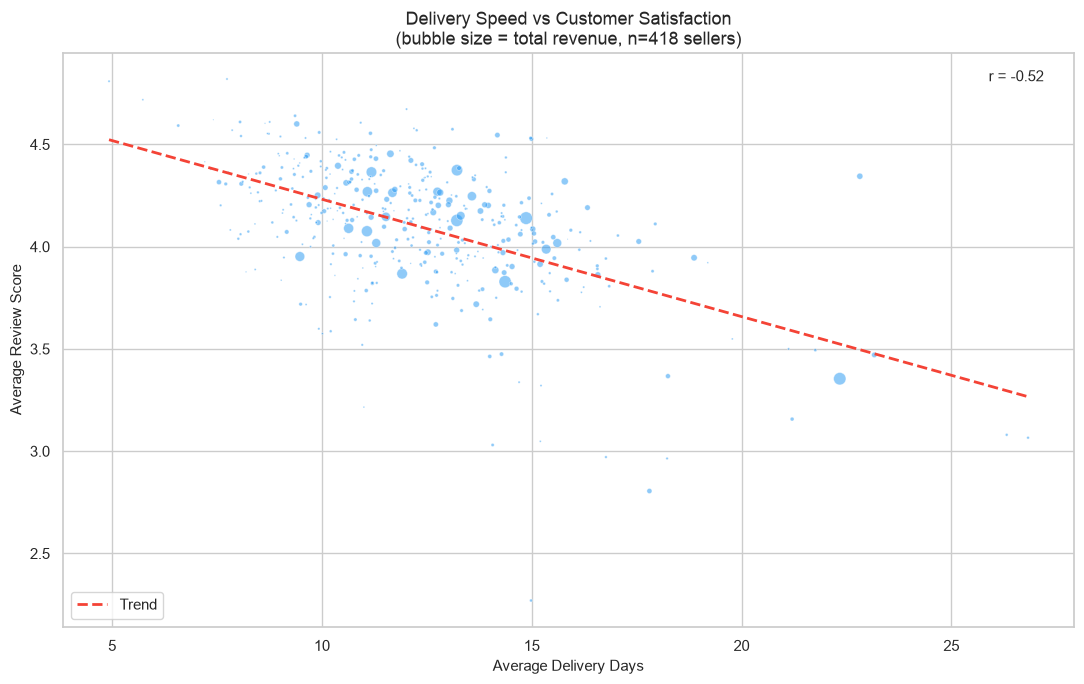

In [ ]:
fig, ax = plt.subplots(figsize=(11, 7))

scatter = ax.scatter(seller_performance['avg_delivery_days'],
                     seller_performance['avg_review_score'],
                     s=seller_performance['total_revenue'] / 3000,
                     alpha=0.5, color='#2196F3', edgecolor='white', linewidth=0.5)

# Add trend line
z = np.polyfit(seller_performance['avg_delivery_days'], 
               seller_performance['avg_review_score'], 1)
p = np.poly1d(z)
x_line = np.linspace(seller_performance['avg_delivery_days'].min(),
                     seller_performance['avg_delivery_days'].max(), 100)
ax.plot(x_line, p(x_line), color='#F44336', linewidth=2, linestyle='--', label='Trend')

# Correlation annotation
corr = seller_performance['avg_delivery_days'].corr(seller_performance['avg_review_score'])
ax.text(0.97, 0.97, f'r = {corr:.2f}', transform=ax.transAxes,
        ha='right', va='top', fontsize=11,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))

ax.set_xlabel('Average Delivery Days', fontsize=11)
ax.set_ylabel('Average Review Score', fontsize=11)
ax.set_title('Delivery Speed vs Customer Satisfaction\n(point size = total revenue, n=418 sellers)',
             fontsize=13)
ax.legend()

plt.tight_layout()
plt.show()

### Delivery Speed and Customer Satisfaction

Across 418 sellers with 50+ delivered orders, average delivery time is moderately 
negatively correlated with review score (r = -0.52): sellers who deliver faster 
tend to receive higher ratings. However, delivery speed explains only ~27% of the 
variance in review scores, indicating that other factors — product quality, listing 
accuracy, and seller communication — play a substantial role in customer satisfaction.

For Olist, this suggests that platform-wide delivery improvements would lift average 
review scores but would not fully close the gap between high- and low-rated sellers. 
Targeted interventions for sellers with both slow delivery AND low review scores 
would be the highest-leverage approach.

## Overall Conclusions

This analysis used SQL (DuckDB) to examine revenue patterns and seller performance 
across ~99K orders on the Olist Brazilian e-commerce marketplace between 2017 and 2018.

**Key findings:**

1. **Revenue growth is broad-based but acquisition-driven.** Monthly revenue grew 
   consistently through 2018 across all top categories, but average order value 
   remained flat at ~R$160–180. With a repeat customer rate of only 3%, growth is 
   almost entirely dependent on new customer acquisition — a structurally fragile 
   model that leaves significant retention upside untapped.

2. **Category economics vary widely.** Health & beauty leads in total revenue through 
   consistent volume, while computers and home appliances command the highest average 
   order values (R$1,290 and R$521). No category achieves both high volume and high 
   AOV simultaneously — a pattern typical of competitive marketplaces where popular 
   categories face price compression.

3. **Black Friday is a platform-wide demand event.** The November 2017 spike is 
   visible across nearly every category, confirming that seasonal demand strategy 
   should be coordinated at the platform level rather than managed category by category.

4. **Delivery speed is a meaningful but incomplete predictor of customer satisfaction.** 
   Faster delivery correlates moderately with higher review scores (r = -0.52), but 
   explains only ~27% of score variance. Targeting sellers with both slow delivery 
   and low review scores represents the highest-leverage intervention for improving 
   platform quality.

**Limitations:** Seller identities are anonymized, preventing category-level seller 
analysis. The 3% repeat customer rate may undercount true retention if customers 
return to sellers through direct channels outside the Olist platform.